# 3D Gaussian Splatting (Splatfacto) — bear-mask

Trains Nerfstudio's **splatfacto** on the masked bear capture and saves the model, rendered
comparisons and training metrics to Google Drive.

**Before running**
1. *Runtime → Change runtime type →* a **GPU** (T4 works; L4/A100 is faster).
2. Upload `data/nerfstudio/bear-mask.zip` from the repo to **`MyDrive/3d-reconstruction/bear-mask.zip`**
   (upload the zip as-is, don't unzip it). It was produced locally by `scripts/prepare_nerfstudio.py` from the
   undistorted COLMAP model (`colmap/bear-mask/dense/0`): 87 images at 1600×1062, stored as RGBA PNGs whose
   alpha is the rembg mask warped into the undistorted camera, plus `transforms.json` and `sparse_pc.ply`.
3. Run the cells top to bottom. **Section 2 restarts the runtime once after installing** (Colab shows a
   "session crashed" notice — that's intended). Then continue from section 3. Every shell command is echoed
   and appended to a log on Drive, and each stage checks its outputs before moving on.

**Settings shared with the other notebook (keep them identical for a fair comparison)**
`--pipeline.model.background-color white` (the alpha matte is composited onto white),
`nerfstudio-data --downscale-factor 1 --eval-mode interval --eval-interval 8`
(every 8th image is held out for evaluation, 11 of 87).

## 1. GPU check

In [1]:
!nvidia-smi

Tue Nov 17 10:41:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   48C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install Nerfstudio (restarts the runtime)

* `gsplat==1.4.0` is pinned by `nerfstudio==1.1.5`. Its prebuilt wheels only cover Python 3.10, and Colab
  runs a newer Python, so it is installed with `BUILD_NO_CUDA=1`. Its CUDA kernels are then JIT-compiled the first
  time they are used. Section 4 triggers that compile (≈5–15 min, once per runtime).
* Pip will warn about conflicts with Colab's preinstalled packages (protobuf, opencv, tensorflow). These are expected.
* Nerfstudio downgrades protobuf and opencv, so the cell kills the runtime after installing to make sure nothing
  stale stays loaded. Colab reconnects automatically. **Continue from section 3.** Re-running this cell later
  (or after a restart) skips the install.

In [ ]:
import importlib.util, os, sys
print(sys.version)

if importlib.util.find_spec('nerfstudio') is None:
    !pip install -q ninja
    !BUILD_NO_CUDA=1 pip install -q gsplat==1.4.0
    !pip install -q nerfstudio==1.1.5
    assert importlib.util.find_spec('nerfstudio') is not None, 'nerfstudio install failed — see the pip output above'
    print('Installed. Restarting the runtime now; continue from section 3.')
    os.kill(os.getpid(), 9)
else:
    print('nerfstudio already installed — skipping')

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 3.20.3 which is incompatible.
grain 0.2.18 requires protobuf>=5.28.3, but you have protobuf 3.20.3 which is incompatible.
google-cloud-spanner 3.71.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
tensorflow-metadata 1.21.0 requires

## 3. Mount Drive and set paths
Run this after every runtime restart. Outputs go to Drive so they survive a disconnect.

In [1]:
import os
from google.colab import drive

drive.mount('/content/drive')

DRIVE_ROOT = '/content/drive/MyDrive/3d-reconstruction'
DATA_ZIP = f'{DRIVE_ROOT}/bear-mask.zip'
DATA = '/content/data/bear-mask'                # unzipped to fast local disk
TEST_OUT = '/content/test_runs'                 # smoke test, not kept
OUT = f'{DRIVE_ROOT}/results/splatfacto'          # full run, kept on Drive
LOG_DIR = f'{OUT}/logs'
os.makedirs(LOG_DIR, exist_ok=True)

# Nerfstudio 1.1.5 calls torch.load() without weights_only; torch>=2.6 defaults it to True,
# which breaks resuming, ns-eval, ns-render and ns-export.
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
assert os.path.exists(DATA_ZIP), f'Upload bear-mask.zip to {DATA_ZIP}'

Mounted at /content/drive


## 4. Verify the environment

In [2]:
import torch, nerfstudio, gsplat
from importlib.metadata import version
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '|', torch.cuda.get_device_name(0))
print('nerfstudio', version('nerfstudio'), '| gsplat', gsplat.__version__)
assert torch.cuda.is_available()

# Force gsplat's JIT CUDA build now (only for this GPU's architecture) and render a tiny scene.
# ns-train inherits TORCH_CUDA_ARCH_LIST and reuses the cached build.
major, minor = torch.cuda.get_device_capability()
os.environ['TORCH_CUDA_ARCH_LIST'] = f'{major}.{minor}'
from gsplat import rasterization
n = 100
means = torch.randn(n, 3, device='cuda') + torch.tensor([0, 0, 5.0], device='cuda')
quats = torch.randn(n, 4, device='cuda')
scales = torch.rand(n, 3, device='cuda') * 0.1
K = torch.tensor([[[100.0, 0, 50], [0, 100, 50], [0, 0, 1]]], device='cuda')
img, alpha, _ = rasterization(means, quats, scales, torch.rand(n, device='cuda'),
                              torch.rand(n, 3, device='cuda'), torch.eye(4, device='cuda')[None], K, 100, 100)
assert img.shape == (1, 100, 100, 3) and alpha.max() > 0
print('gsplat rasterization OK')

torch 2.14.1+cu130 | CUDA 13.0 | NVIDIA L4
nerfstudio 1.1.5 | gsplat 1.4.0


Output()

gsplat rasterization OK


## 5. Unpack and check the dataset

87 frames | 87 images | 1600 x 1062 | RGBA


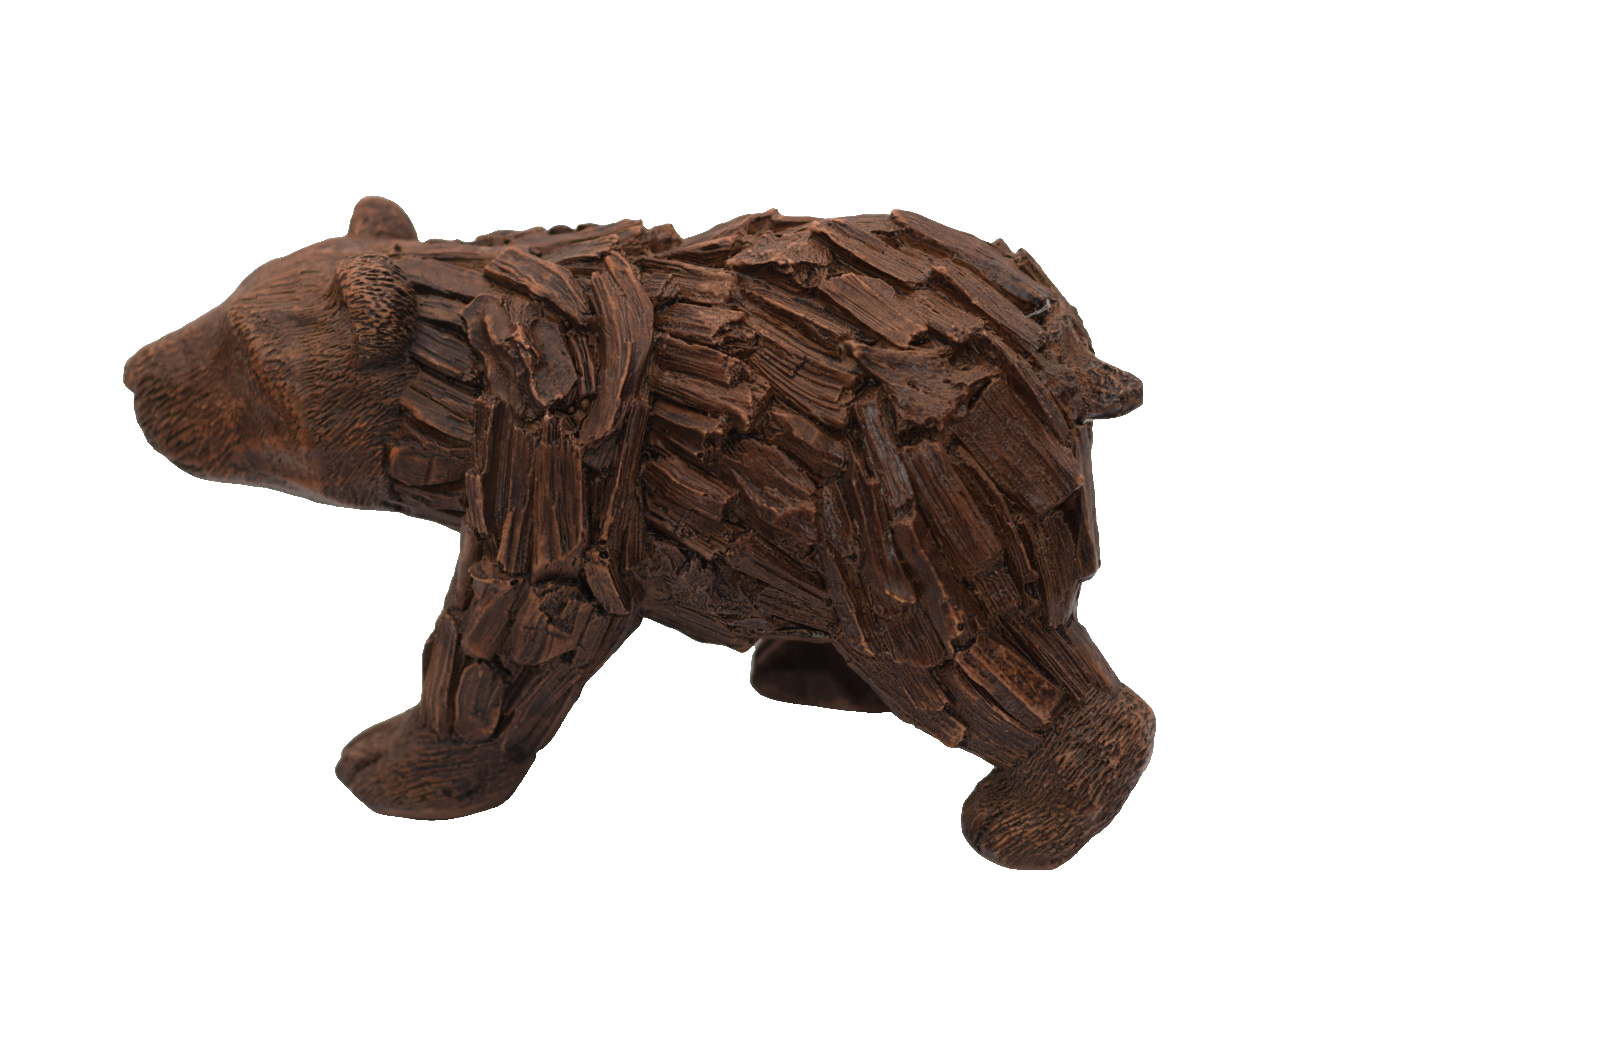

In [3]:
import json, zipfile
from PIL import Image

if not os.path.exists(f'{DATA}/transforms.json'):
    zipfile.ZipFile(DATA_ZIP).extractall('/content/data')

meta = json.load(open(f'{DATA}/transforms.json'))
images = sorted(os.listdir(f'{DATA}/images'))
first = Image.open(f"{DATA}/{meta['frames'][0]['file_path']}")
print(len(meta['frames']), 'frames |', len(images), 'images |', meta['w'], 'x', meta['h'], '|', first.mode)
assert len(meta['frames']) == len(images) == 87
assert first.mode == 'RGBA' and first.size == (meta['w'], meta['h'])
assert meta.get('ply_file_path') == 'sparse_pc.ply' and os.path.exists(f'{DATA}/sparse_pc.ply')
first

## 6. Helpers
`sh()` streams a command's output, appends it to a log file and raises if it fails.

In [4]:
import glob, subprocess, sys

def sh(cmd, log):
    print('$', cmd, flush=True)
    with open(log, 'a') as f, subprocess.Popen(cmd, shell=True, text=True, bufsize=1,
                                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT) as p:
        f.write(f'$ {cmd}\n')
        for line in p.stdout:
            sys.stdout.write(line)
            f.write(line)
    if p.returncode:
        raise RuntimeError(f'exit code {p.returncode} — see {log}')

def train_cmd(out_dir, timestamp, iters, resume_dir=None):
    # NB: ns-train runs `--max-num-iterations` steps *after* the loaded checkpoint, not up to it.
    cmd = (f'ns-train splatfacto --data {DATA} --output-dir {out_dir} --experiment-name bear-mask '
           f'--timestamp {timestamp} --vis tensorboard --max-num-iterations {iters} '
           f'--steps-per-save 2000 --pipeline.model.background-color white ')
    if resume_dir:
        cmd += f'--load-dir {resume_dir} '
    return cmd + 'nerfstudio-data --downscale-factor 1 --eval-mode interval --eval-interval 8 --load-3D-points True'

def run_dir(out_dir, timestamp):
    return f'{out_dir}/bear-mask/splatfacto/{timestamp}'

def checkpoints(run):
    return sorted(glob.glob(f'{run}/nerfstudio_models/step-*.ckpt'))

def ckpt_step(path):
    return int(os.path.basename(path)[5:-5])   # step-000029999.ckpt -> 29999

## 7. Smoke test (1000 iterations)
Checks the whole chain (training, checkpointing, evaluation) on a short run before the full job.

In [5]:
TEST_LOG = f'{LOG_DIR}/test_train.log'
open(TEST_LOG, 'w').close()   # fresh log on every attempt
sh(train_cmd(TEST_OUT, 'test', 1000), TEST_LOG)

test_run = run_dir(TEST_OUT, 'test')
assert checkpoints(test_run), 'no checkpoint written'
print('checkpoint:', checkpoints(test_run)[-1])

# Confirm the gaussians were initialised from the COLMAP points rather than at random.
# (Rich wraps long lines in the log, so compare with whitespace collapsed.)
log_text = ' '.join(open(TEST_LOG).read().split())
assert 'random point cloud initialization' not in log_text, 'sparse_pc.ply was not loaded'

sh(f'ns-eval --load-config {test_run}/config.yml --output-path {test_run}/eval.json', f'{LOG_DIR}/test_eval.log')
print(json.load(open(f'{test_run}/eval.json'))['results'])

$ ns-train splatfacto --data /content/data/bear-mask --output-dir /content/test_runs --experiment-name bear-mask --timestamp test --vis tensorboard --max-num-iterations 1000 --steps-per-save 2000 --pipeline.model.background-color white nerfstudio-data --downscale-factor 1 --eval-mode interval --eval-interval 8 --load-3D-points True
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794913224.136330    6353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794913224.207348    6353 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instru

## 8. Full training (30,000 iterations)
Roughly 20–60 min depending on GPU.
Checkpoints are written to Drive every 2,000 steps. If the runtime disconnects, re-run sections 3–6 and
then this cell. It resumes from the latest checkpoint and trains only the remaining steps. Once training is
complete, re-running this cell does nothing.

In [6]:
ITERS = 30000
RUN = run_dir(OUT, 'full')
done = checkpoints(RUN)
start = ckpt_step(done[-1]) + 1 if done else 0

if start >= ITERS:
    print('already trained to step', start - 1)
else:
    print(f'resuming from step {start}' if done else 'training from scratch')
    sh(train_cmd(OUT, 'full', ITERS - start, f'{RUN}/nerfstudio_models' if done else None),
       f'{LOG_DIR}/full_train.log')

last = checkpoints(RUN)[-1]
print('final checkpoint:', last)
assert ckpt_step(last) == ITERS - 1, 'training stopped before the last step'

Streaming output truncated to the last 5000 lines.

Step (% Done)       Train Iter (time)    ETA (time)           Train Rays / Sec     Test Rays / Sec       
-------------------------------------------------------------------------------------------------------- 
26360 (87.87%)      25.385 ms            1 m, 32 s            67.20 M                                    
26370 (87.90%)      25.392 ms            1 m, 32 s            67.22 M                                    
26380 (87.93%)      25.555 ms            1 m, 32 s            66.77 M                                    
26390 (87.97%)      25.491 ms            1 m, 32 s            66.85 M                                    
26400 (88.00%)      25.023 ms            1 m, 30 s            68.09 M              53.19 M               
26410 (88.03%)      33.900 ms            2 m, 1 s             65.24 M                                    
26420 (88.07%)      33.943 ms            2 m, 1 s             65.06 M                               

## 9. Evaluate on the held-out images
`ns-eval` reports PSNR/SSIM/LPIPS averaged over the 11 eval views. For each view it saves a
side-by-side **ground truth | render** image (`eval_img_XXXX.png`).

In [7]:
EVAL_DIR = f'{RUN}/eval'
sh(f'ns-eval --load-config {RUN}/config.yml --output-path {EVAL_DIR}/metrics.json '
   f'--render-output-path {EVAL_DIR}/comparisons', f'{LOG_DIR}/eval.log')

results = json.load(open(f'{EVAL_DIR}/metrics.json'))['results']
for k, v in results.items():
    print(f'{k:>16}: {v:.4f}')
comparisons = sorted(glob.glob(f'{EVAL_DIR}/comparisons/eval_img_*.png'))
assert len(comparisons) == 11, len(comparisons)

$ ns-eval --load-config /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/config.yml --output-path /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/eval/metrics.json --render-output-path /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/eval/comparisons
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794914299.142176   11146 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794914299.216467   11146 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
T

eval_img_0000.png — left: ground truth, right: render


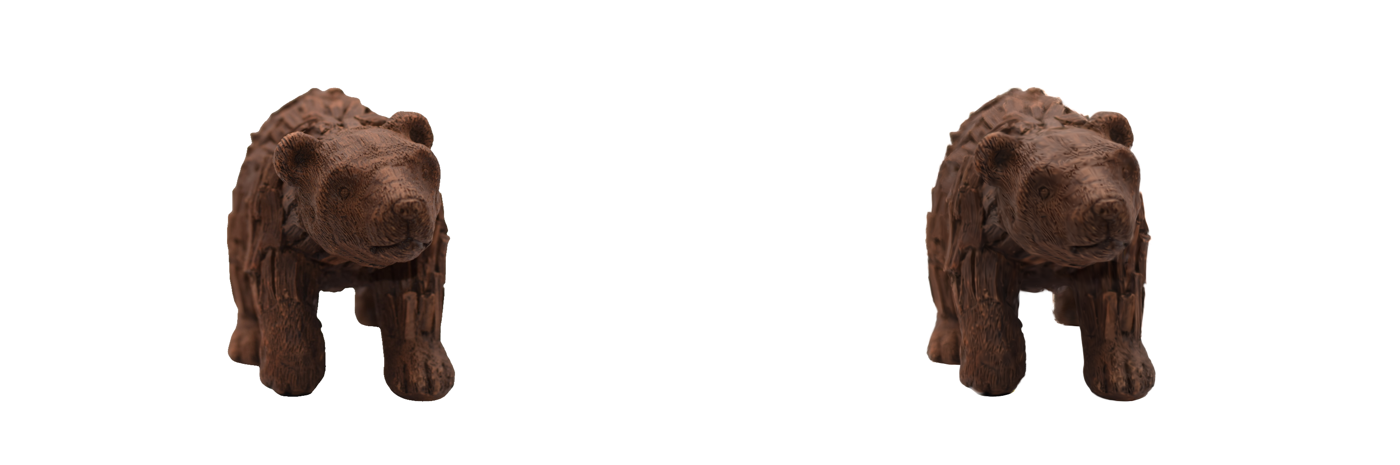

eval_img_0001.png — left: ground truth, right: render


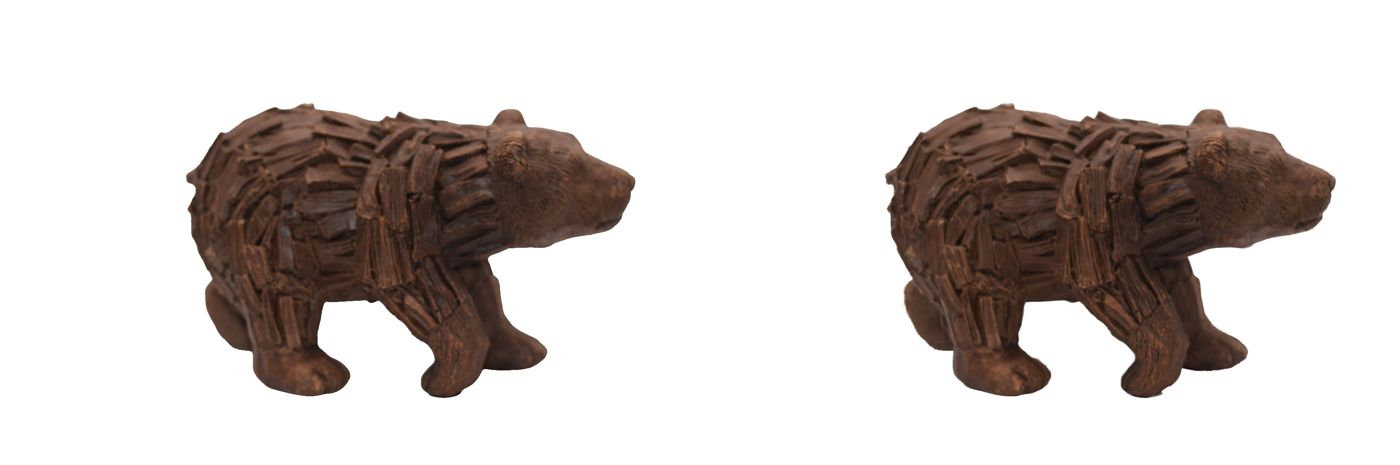

eval_img_0002.png — left: ground truth, right: render


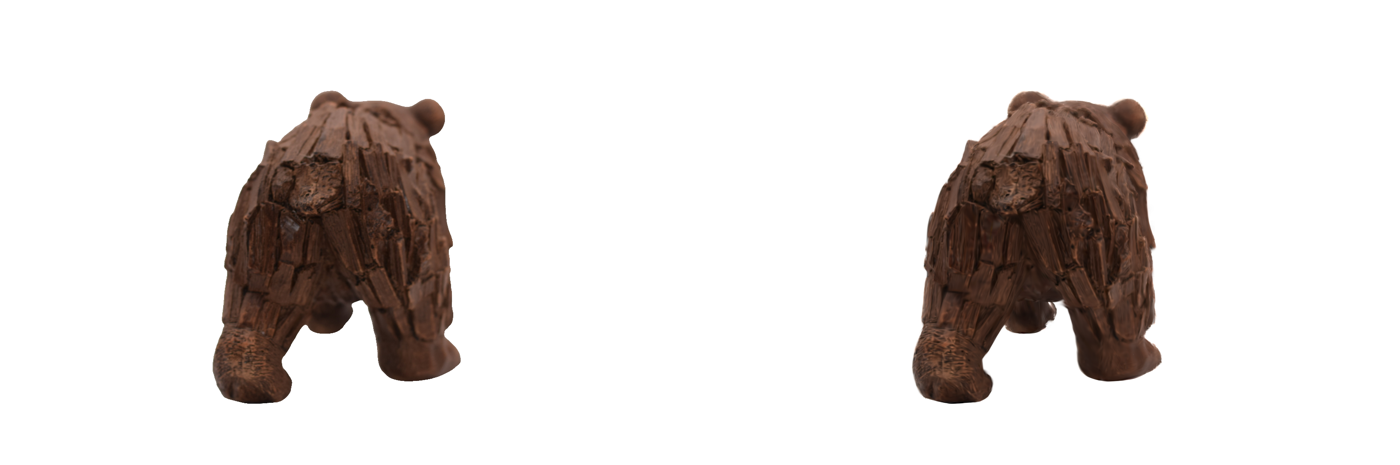

eval_img_0003.png — left: ground truth, right: render


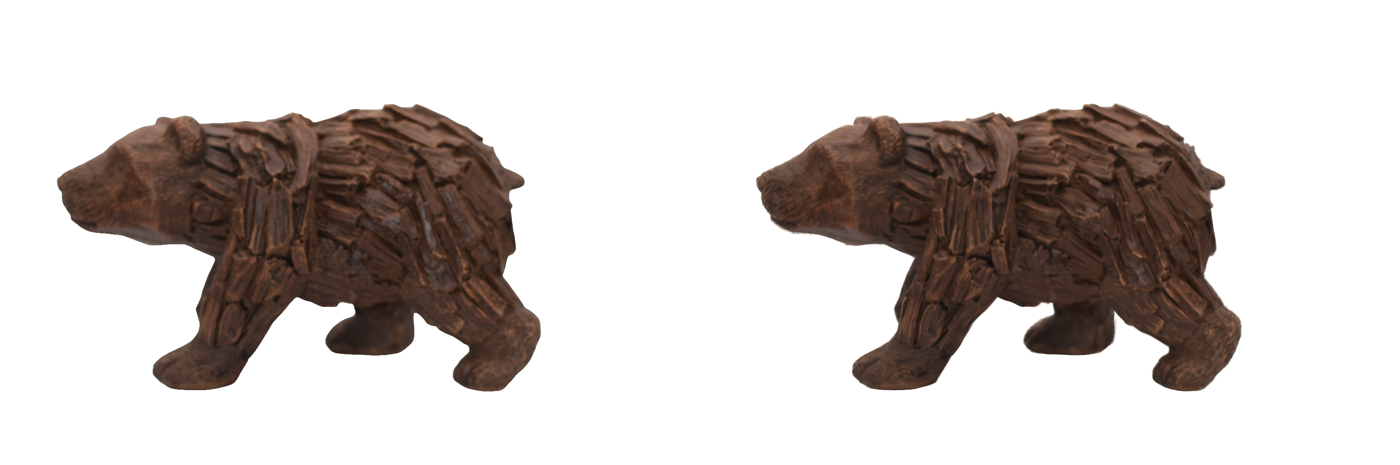

In [8]:
from IPython.display import display
for path in comparisons[:4]:
    print(os.path.basename(path), '— left: ground truth, right: render')
    im = Image.open(path)
    im.thumbnail((1400, 1400))
    display(im)

## 10. Training curves
Exports every TensorBoard scalar to CSV and plots the loss and PSNR curves. If training was resumed, steps
logged after the last checkpoint of the interrupted run are replaced by the resumed run's values.

['ETA (time)', 'Eval Images Metrics Dict (all images)/fps', 'Eval Images Metrics Dict (all images)/lpips', 'Eval Images Metrics Dict (all images)/num_rays_per_sec', 'Eval Images Metrics Dict (all images)/psnr', 'Eval Images Metrics Dict (all images)/ssim', 'Eval Images Metrics/lpips', 'Eval Images Metrics/num_rays', 'Eval Images Metrics/psnr', 'Eval Images Metrics/ssim', 'GPU Memory (MB)', 'Test Rays / Sec', 'Train Iter (time)', 'Train Loss', 'Train Loss Dict/main_loss', 'Train Loss Dict/scale_reg', 'Train Metrics Dict/gaussian_count', 'Train Metrics Dict/psnr', 'Train Rays / Sec', 'Train Total (time)', 'learning_rate/means']


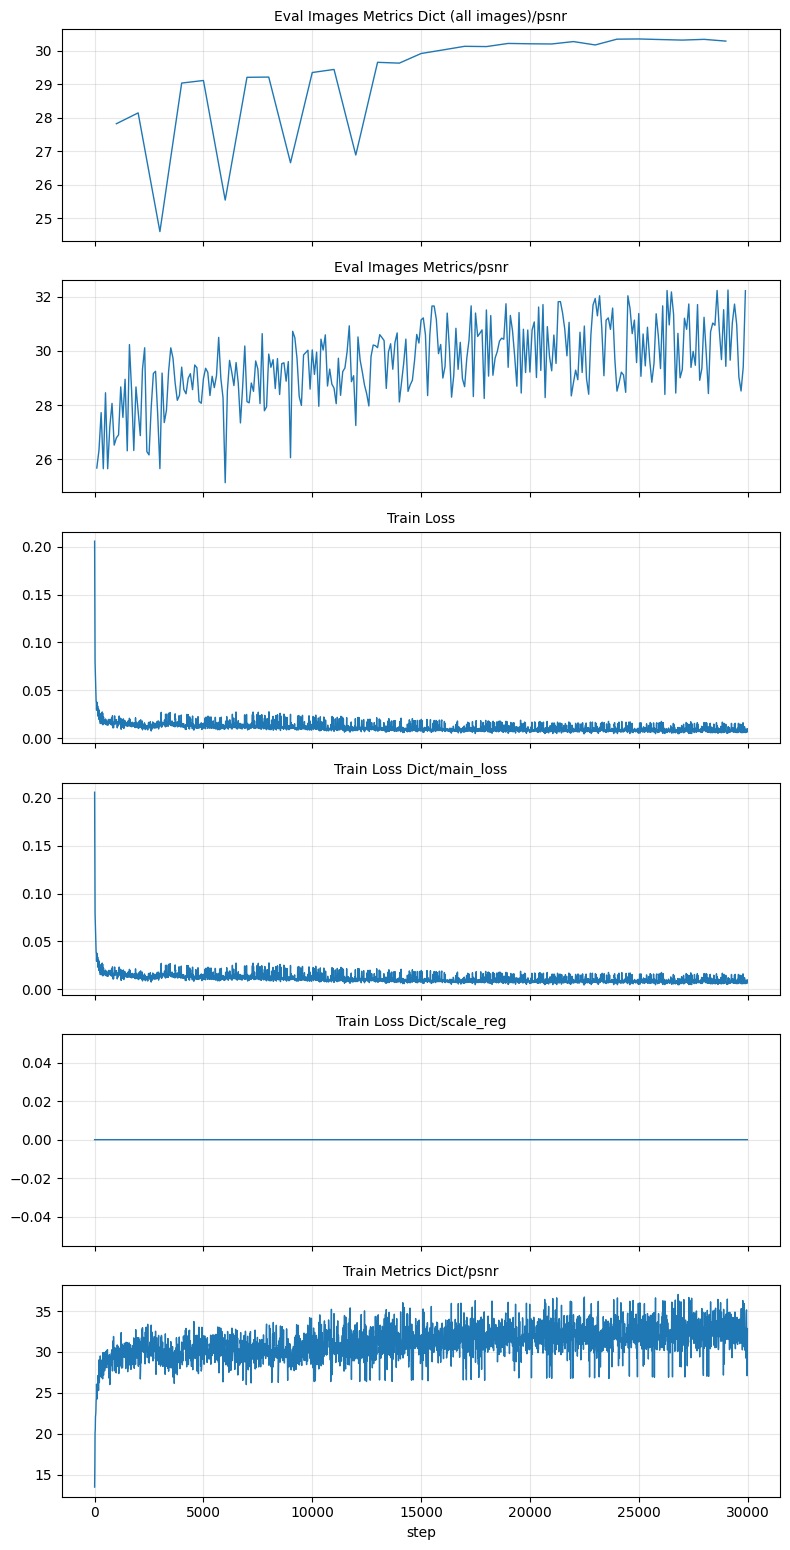

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ea = EventAccumulator(RUN, size_guidance={'scalars': 0})
ea.Reload()
rows = [(tag, e.wall_time, e.step, e.value) for tag in ea.Tags()['scalars'] for e in ea.Scalars(tag)]
scalars = (pd.DataFrame(rows, columns=['tag', 'wall_time', 'step', 'value'])
           .sort_values('wall_time').drop_duplicates(['tag', 'step'], keep='last')
           .sort_values(['tag', 'step']).drop(columns='wall_time'))
os.makedirs(f'{RUN}/metrics', exist_ok=True)
scalars.to_csv(f'{RUN}/metrics/training_scalars.csv', index=False)
print(sorted(scalars.tag.unique()))

tags = [t for t in scalars.tag.unique() if any(s in t.lower() for s in ('loss', 'psnr'))]
assert tags, 'no loss/psnr scalars found'
fig, axes = plt.subplots(len(tags), 1, figsize=(8, 2.6 * len(tags)), sharex=True, squeeze=False)
axes = axes[:, 0]
for ax, tag in zip(axes, tags):
    d = scalars[scalars.tag == tag]
    ax.plot(d.step, d.value, lw=1)
    ax.set_title(tag, fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('step')
fig.tight_layout()
fig.savefig(f'{RUN}/metrics/training_curves.png', dpi=150)

## 11. Fly-through video
Interpolates between the training camera poses and renders at half resolution.

In [10]:
VIDEO = f'{RUN}/renders/interpolate.mp4'
sh(f'ns-render interpolate --load-config {RUN}/config.yml --output-path {VIDEO} '
   f'--pose-source train --order-poses True --interpolation-steps 3 --frame-rate 24 --downscale-factor 2',
   f'{LOG_DIR}/render.log')
assert os.path.getsize(VIDEO) > 0

from IPython.display import Video
Video(VIDEO, embed=True, width=800)

$ ns-render interpolate --load-config /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/config.yml --output-path /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/renders/interpolate.mp4 --pose-source train --order-poses True --interpolation-steps 3 --frame-rate 24 --downscale-factor 2
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794914399.618296   11690 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794914399.688623   11690 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To en

## 12. Export the Gaussian splat
Writes `splat.ply`, which standard 3DGS viewers can open (e.g. SuperSplat, or the antimatter15 splat viewer).

In [11]:
EXPORT = f'{RUN}/export'
sh(f'ns-export gaussian-splat --load-config {RUN}/config.yml --output-dir {EXPORT}', f'{LOG_DIR}/export.log')
assert os.path.exists(f'{EXPORT}/splat.ply')
print(round(os.path.getsize(f'{EXPORT}/splat.ply') / 1e6, 1), 'MB')

$ ns-export gaussian-splat --load-config /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/config.yml --output-dir /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/export
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794914424.225267   11945 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794914424.295401   11945 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the app

## 13. What was saved to Drive

In [12]:
for dirpath, _, files in sorted(os.walk(OUT)):
    for name in sorted(files):
        p = os.path.join(dirpath, name)
        if 'comparisons' not in p:
            print(f'{os.path.getsize(p) / 1e6:9.1f} MB  {os.path.relpath(p, OUT)}')
print(len(comparisons), 'comparison images in', f'{EVAL_DIR}/comparisons')

      0.0 MB  bear-mask/splatfacto/full/config.yml
      0.0 MB  bear-mask/splatfacto/full/dataparser_transforms.json
    285.6 MB  bear-mask/splatfacto/full/events.out.tfevents.1794913327.7acff501a4a4.6947.0
      0.0 MB  bear-mask/splatfacto/full/eval/metrics.json
     12.9 MB  bear-mask/splatfacto/full/export/splat.ply
      0.3 MB  bear-mask/splatfacto/full/metrics/training_curves.png
      5.7 MB  bear-mask/splatfacto/full/metrics/training_scalars.csv
     46.9 MB  bear-mask/splatfacto/full/nerfstudio_models/step-000029999.ckpt
      0.7 MB  bear-mask/splatfacto/full/renders/interpolate.mp4
      0.0 MB  logs/eval.log
      0.0 MB  logs/export.log
      4.0 MB  logs/full_train.log
      0.0 MB  logs/render.log
      0.0 MB  logs/test_eval.log
      0.1 MB  logs/test_train.log
11 comparison images in /content/drive/MyDrive/3d-reconstruction/results/splatfacto/bear-mask/splatfacto/full/eval/comparisons
